In [ ]:
# ==========================================================
# IMPORT LIBRARIES
# ==========================================================

import os
import warnings

import joblib
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import LabelEncoder

from sklearn.metrics import (

    accuracy_score,

    precision_score,

    recall_score,

    f1_score,

    confusion_matrix,

    classification_report

)

from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

In [ ]:
# ==========================================================
# FILE PATHS
# ==========================================================

DATASET_FILE = "/content/drive/MyDrive/Exoplanet_Dataset/11_Training_Dataset/Training_Dataset.csv"

MODEL_FOLDER = "/content/drive/MyDrive/Exoplanet_Dataset/07_Models"

os.makedirs(

    MODEL_FOLDER,

    exist_ok=True

)

MODEL_FILE = os.path.join(

    MODEL_FOLDER,

    "XGBoost_Model.joblib"

)

print("="*60)
print("PATHS LOADED")
print("="*60)

print()

print(DATASET_FILE)
print(MODEL_FILE)

PATHS LOADED

/content/drive/MyDrive/Exoplanet_Dataset/11_Training_Dataset/Training_Dataset.csv
/content/drive/MyDrive/Exoplanet_Dataset/07_Models/XGBoost_Model.joblib


In [ ]:
# ==========================================================
# LOAD DATASET
# ==========================================================

dataset = pd.read_csv(

    DATASET_FILE

)

print("="*60)
print("TRAINING DATASET")
print("="*60)

print()

print("Rows :", len(dataset))

print("Columns :", len(dataset.columns))

print()

display(

    dataset.head()

)

TRAINING DATASET

Rows : 1172
Columns : 23



,TIC_ID,Label,Number_of_Sectors,Best_Sector,period_days,duration_days,epoch_days,bls_depth,bls_power,peak_sigma,...,ingress_phase,red_chi2,rms_resid,ingress_fraction,flat_bottom_fraction,transit_snr,odd_even_ratio,secondary_depth,secondary_snr,duty_cycle
0,737546,EB,1,5,3.079013,0.183,1441.146152,0.176721,6.905140e+06,9.223567,...,0.029717,1520.997363,0.057988,0.316427,0.367147,4.386221,1.096883,30812.446592,0.938785,0.093915
1,927579,EB,3,8,7.313719,0.138,1522.313799,0.007182,9.297943e+01,4.108305,...,0.002863,0.965778,0.007335,0.140704,0.718592,0.868916,NaN,403.933092,0.056066,0.020348
2,1528696,Planet,3,98,0.881897,0.030,3994.614357,0.007043,7.459962e+02,43.508619,...,0.014395,0.996197,0.016563,0.385253,0.229493,0.381656,1.010677,417.090013,0.025352,0.037364
3,1950736,False Positive,2,73,0.777963,0.210,3285.981604,0.000118,2.110125e+01,7.311826,...,0.134968,0.982580,0.001067,0.431389,0.137221,0.107664,5.257057,0.000000,0.000000,0.312868
4,2234723,EB,9,43,0.616019,0.249,2474.387552,0.003113,2.089008e+05,25.419678,...,0.196293,18.013362,0.001676,0.439327,0.121346,2.430875,1.240329,0.000000,0.000000,0.446803


In [ ]:
# ==========================================================
# FEATURE SELECTION
# ==========================================================

FEATURE_COLUMNS = [

    "period_days",

    "duration_days",

    "bls_depth",

    "bls_power",

    "peak_sigma",

    "depth_ppm",

    "T_tot_hours",

    "T_in_hours",

    "ingress_phase",

    "red_chi2",

    "rms_resid",

    "ingress_fraction",

    "flat_bottom_fraction",

    "transit_snr",

    "odd_even_ratio",

    "secondary_depth",

    "secondary_snr",

    "duty_cycle"

]

TARGET_COLUMN = "Label"

X = dataset[

    FEATURE_COLUMNS

]

y = dataset[

    TARGET_COLUMN

]

print("="*60)
print("FEATURE MATRIX")
print("="*60)

print()

print("X Shape :", X.shape)

print("y Shape :", y.shape)

print()

print("Features")

for feature in FEATURE_COLUMNS:

    print(feature)

FEATURE MATRIX

X Shape : (1172, 18)
y Shape : (1172,)

Features
period_days
duration_days
bls_depth
bls_power
peak_sigma
depth_ppm
T_tot_hours
T_in_hours
ingress_phase
red_chi2
rms_resid
ingress_fraction
flat_bottom_fraction
transit_snr
odd_even_ratio
secondary_depth
secondary_snr
duty_cycle


In [ ]:
# ==========================================================
# LABEL ENCODING
# ==========================================================

encoder = LabelEncoder()

y = encoder.fit_transform(y)

print("=" * 60)
print("LABEL ENCODING")
print("=" * 60)

label_mapping = dict(

    zip(

        encoder.classes_,

        encoder.transform(

            encoder.classes_

        )

    )

)

print()

for label, value in label_mapping.items():

    print(f"{label:18s} -> {value}")

LABEL ENCODING

EB                 -> 0
False Positive     -> 1
Planet             -> 2


In [ ]:
# ==========================================================
# TRAIN / TEST SPLIT
# ==========================================================

X_train, X_test, y_train, y_test = train_test_split(

    X,

    y,

    test_size=0.20,

    stratify=y,

    random_state=42

)

print("=" * 60)
print("TRAIN / TEST SPLIT")
print("=" * 60)

print()

print("Training :", X_train.shape)

print("Testing  :", X_test.shape)

TRAIN / TEST SPLIT

Training : (937, 18)
Testing  : (235, 18)


In [ ]:
# ==========================================================
# CLASS DISTRIBUTION
# ==========================================================

def class_distribution(name, labels):

    counts = pd.Series(

        encoder.inverse_transform(labels)

    ).value_counts()

    print()

    print(name)

    print(counts)

class_distribution(

    "Training",

    y_train

)

class_distribution(

    "Testing",

    y_test

)


Training
EB                320
Planet            319
False Positive    298
Name: count, dtype: int64

Testing
Planet            80
EB                80
False Positive    75
Name: count, dtype: int64


In [ ]:
# ==========================================================
# TRAIN REGULARIZED XGBOOST
# ==========================================================

model = XGBClassifier(

    objective="multi:softprob",

    num_class=3,

    n_estimators=150,

    max_depth=3,

    learning_rate=0.05,

    subsample=0.8,

    colsample_bytree=0.8,

    min_child_weight=5,

    gamma=0.3,

    reg_alpha=0.5,

    reg_lambda=2.0,

    eval_metric="mlogloss",

    random_state=42,

    tree_method="hist"

)

print("=" * 60)
print("TRAINING REGULARIZED XGBOOST")
print("=" * 60)

model.fit(
    X_train,
    y_train
)

print()
print("Training Complete!")

TRAINING REGULARIZED XGBOOST

Training Complete!


In [ ]:
# ==========================================================
# PREDICTIONS
# ==========================================================

train_predictions = model.predict(

    X_train

)

test_predictions = model.predict(

    X_test

)

print("=" * 60)
print("PREDICTIONS COMPLETE")
print("=" * 60)

PREDICTIONS COMPLETE


In [ ]:
# ==========================================================
# MODEL PERFORMANCE
# ==========================================================

print("=" * 60)
print("TRAINING PERFORMANCE")
print("=" * 60)

print()

print(

    "Accuracy :",

    round(

        accuracy_score(

            y_train,

            train_predictions

        ),

        4

    )

)

print(

    "Precision:",

    round(

        precision_score(

            y_train,

            train_predictions,

            average="weighted"

        ),

        4

    )

)

print(

    "Recall   :",

    round(

        recall_score(

            y_train,

            train_predictions,

            average="weighted"

        ),

        4

    )

)

print(

    "F1 Score :",

    round(

        f1_score(

            y_train,

            train_predictions,

            average="weighted"

        ),

        4

    )

)

print()

print("=" * 60)
print("TEST PERFORMANCE")
print("=" * 60)

print()

print(

    "Accuracy :",

    round(

        accuracy_score(

            y_test,

            test_predictions

        ),

        4

    )

)

print(

    "Precision:",

    round(

        precision_score(

            y_test,

            test_predictions,

            average="weighted"

        ),

        4

    )

)

print(

    "Recall   :",

    round(

        recall_score(

            y_test,

            test_predictions,

            average="weighted"

        ),

        4

    )

)

print(

    "F1 Score :",

    round(

        f1_score(

            y_test,

            test_predictions,

            average="weighted"

        ),

        4

    )

)

TRAINING PERFORMANCE

Accuracy : 0.8815
Precision: 0.8843
Recall   : 0.8815
F1 Score : 0.8825

TEST PERFORMANCE

Accuracy : 0.7915
Precision: 0.7915
Recall   : 0.7915
F1 Score : 0.7915


In [ ]:
# ==========================================================
# CLASSIFICATION REPORT
# ==========================================================

print("=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)

print(

    classification_report(

        y_test,

        test_predictions,

        target_names=encoder.classes_

    )

)

CLASSIFICATION REPORT
                precision    recall  f1-score   support

            EB       0.91      0.91      0.91        80
False Positive       0.71      0.71      0.71        75
        Planet       0.75      0.75      0.75        80

      accuracy                           0.79       235
     macro avg       0.79      0.79      0.79       235
  weighted avg       0.79      0.79      0.79       235



<Figure size 600x600 with 0 Axes>

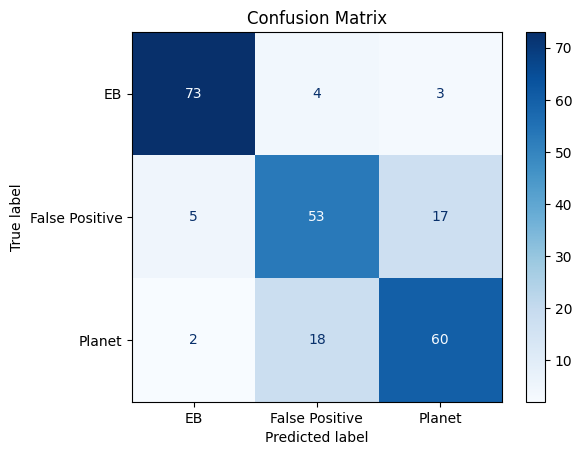

In [ ]:
# ==========================================================
# CONFUSION MATRIX
# ==========================================================
from sklearn.metrics import ConfusionMatrixDisplay
cm = confusion_matrix(

    y_test,

    test_predictions

)

disp = ConfusionMatrixDisplay(

    confusion_matrix=cm,

    display_labels=encoder.classes_

)

plt.figure(figsize=(6,6))

disp.plot(
    values_format="d",
    cmap="Blues"
)

plt.title("Confusion Matrix")

plt.show()

In [ ]:
import pandas as pd

# Load your features file
df = pd.read_csv(
    "/content/drive/MyDrive/Exoplanet_Dataset/11_Training_Dataset_V2/Training_Dataset_V2.csv"
)

print(df.shape)
print(df["Label"].value_counts())

(1172, 31)
Label
EB                400
Planet            399
False Positive    373
Name: count, dtype: int64


In [ ]:
eb = df[df["Label"]=="EB"].sample(1, random_state=42).iloc[0]

print("="*65)
print("       ECLIPSING BINARY REPORT")
print("="*65)

print(f"TIC ID                 : {eb['TIC_ID']}")
print(f"Ground Truth           : {eb['Label']}")

print("\nTransit Parameters")
print("-"*65)
print(f"Orbital Period         : {eb['period_days']:.4f} days")
print(f"Transit Depth          : {eb['depth_ppm']:.0f} ppm")
print(f"Transit Duration       : {eb['T_tot_hours']:.2f} hours")
print(f"Ingress Duration       : {eb['T_in_hours']:.2f} hours")

print("\nPhysics Features")
print("-"*65)
print(f"Transit SNR            : {eb['transit_snr']:.2f}")
print(f"Ingress Fraction       : {eb['ingress_fraction']:.3f}")
print(f"Flat Bottom Fraction   : {eb['flat_bottom_fraction']:.3f}")
print(f"Odd-Even Ratio         : {eb['odd_even_ratio']:.3f}")
print(f"Secondary Depth        : {eb['secondary_depth']:.3f}")

print("\nDetection Statistics")
print("-"*65)
print(f"BLS Power              : {eb['bls_power']:.2f}")
print(f"Peak Significance      : {eb['peak_sigma']:.2f}")

print("="*65)

       ECLIPSING BINARY REPORT
TIC ID                 : 293480903
Ground Truth           : EB

Transit Parameters
-----------------------------------------------------------------
Orbital Period         : 7.5699 days
Transit Depth          : 26449 ppm
Transit Duration       : 2.63 hours
Ingress Duration       : 0.94 hours

Physics Features
-----------------------------------------------------------------
Transit SNR            : 9.89
Ingress Fraction       : 0.356
Flat Bottom Fraction   : 0.288
Odd-Even Ratio         : 1.021
Secondary Depth        : 5620.312

Detection Statistics
-----------------------------------------------------------------
BLS Power              : 32464.14
Peak Significance      : 9.80


In [ ]:
# Columns used for training
X = df.drop(columns=["TIC_ID", "Label"])

# Predict
pred = xgb_model.predict(X)

# Probability
prob = xgb_model.predict_proba(X)

# Attach to dataframe
df["Predicted_Class"] = pred
df["Prediction_Probability"] = prob.max(axis=1)

NameError: name 'xgb_model' is not defined

In [ ]:
eb = df[df["Label"]=="EB"].sample(1, random_state=42).iloc[0]

print("="*70)
print("             EXOPLANET DETECTION REPORT")
print("="*70)

print(f"TIC ID                 : {eb['TIC_ID']}")
print(f"Ground Truth           : {eb['Label']}")
print(f"Predicted Class        : {eb['Predicted_Class']}")
print(f"Prediction Confidence  : {eb['Prediction_Probability']*100:.2f}%")

print("\nTransit Parameters")
print("-"*70)
print(f"Orbital Period         : {eb['period_days']:.4f} days")
print(f"Transit Depth          : {eb['depth_ppm']:.0f} ppm")
print(f"Transit Duration       : {eb['T_tot_hours']:.2f} hours")

print("\nPhysics Features")
print("-"*70)
print(f"Transit SNR            : {eb['transit_snr']:.2f}")
print(f"Ingress Fraction       : {eb['ingress_fraction']:.3f}")
print(f"Flat Bottom Fraction   : {eb['flat_bottom_fraction']:.3f}")
print(f"Odd-Even Ratio         : {eb['odd_even_ratio']:.3f}")
print(f"Secondary Depth        : {eb['secondary_depth']:.0f} ppm")

print("\nDetection Statistics")
print("-"*70)
print(f"BLS Power              : {eb['bls_power']:.2f}")
print(f"Peak Significance      : {eb['peak_sigma']:.2f}")

print("\nFinal Assessment")
print("-"*70)
print("Candidate Status       : REJECTED")
print("Reason                 : Classified as Eclipsing Binary")

print("="*70)

             EXOPLANET DETECTION REPORT
TIC ID                 : 293480903
Ground Truth           : EB


KeyError: 'Predicted_Class'